# House Price Prediction - Machine Learning Project

In this project I am using a house price dataset to predict the price of a house using Machine Learning.

Steps I followed:
1. Problem Understanding
2. Data Understanding
3. X and y
4. EDA (Exploratory Data Analysis)
5. Encoding
6. Train-Test Split
7. Feature Scaling
8. Training the Models
9. Model Evaluation
10. Conclusion

## 1. Problem Understanding

The dataset has details of houses like area, bedrooms, bathrooms, floors, year built, location, condition and garage.

I am doing two things here:
- **Regression** - predict the exact `Price` of the house.
- **Classification** - predict whether the house price is High (1) or Low (0). For this I will use the median price as the cutoff.

## 2. Data Understanding

In [1]:
# importing the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
# reading the csv file
df = pd.read_csv("House_Price_Prediction_Dataset.csv")
df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'House_Price_Prediction_Dataset.csv'

In [ ]:
# how many rows and columns are there
df.shape

(2000, 10)

In [ ]:
# column names, data types and non-null count
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Id         2000 non-null   int64
 1   Area       2000 non-null   int64
 2   Bedrooms   2000 non-null   int64
 3   Bathrooms  2000 non-null   int64
 4   Floors     2000 non-null   int64
 5   YearBuilt  2000 non-null   int64
 6   Location   2000 non-null   str  
 7   Condition  2000 non-null   str  
 8   Garage     2000 non-null   str  
 9   Price      2000 non-null   int64
dtypes: int64(7), str(3)
memory usage: 156.4 KB


In [ ]:
# basic statistics of the numerical columns
df.describe()

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Price
count,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000,2000.000000,2000.000000
mean,1000.500000,2786.209500,3.003500,2.55250,1.993500,1961.446000,537676.855000
std,577.494589,1295.146799,1.424606,1.10899,0.809188,35.926695,276428.845719
min,1.000000,501.000000,1.000000,1.00000,1.000000,1900.000000,50005.000000
25%,500.750000,1653.000000,2.000000,2.00000,1.000000,1930.000000,300098.000000
50%,1000.500000,2833.000000,3.000000,3.00000,2.000000,1961.000000,539254.000000
75%,1500.250000,3887.500000,4.000000,4.00000,3.000000,1993.000000,780086.000000
max,2000.000000,4999.000000,5.000000,4.00000,3.000000,2023.000000,999656.000000


In [ ]:
# checking for null values
df.isnull().sum()

Id           0
Area         0
Bedrooms     0
Bathrooms    0
Floors       0
YearBuilt    0
Location     0
Condition    0
Garage       0
Price        0
dtype: int64

In [ ]:
# checking for duplicate rows
df.duplicated().sum()

np.int64(0)

In [ ]:
# counting the categories in Location
df['Location'].value_counts()

Location
Downtown    558
Urban       485
Suburban    483
Rural       474
Name: count, dtype: int64

In [ ]:
# counting the categories in Condition
df['Condition'].value_counts()

Condition
Fair         521
Excellent    511
Poor         507
Good         461
Name: count, dtype: int64

In [ ]:
# how many houses have garage
df['Garage'].value_counts()

Garage
No     1038
Yes     962
Name: count, dtype: int64

**Observation:**
- The dataset has 2000 rows and 10 columns.
- There are no missing values and no duplicate rows, so no cleaning is needed.
- `Price` is between 50,000 and 1,000,000 approximately.
- `Location`, `Condition` and `Garage` are text columns, so I need to convert them into numbers later.

## 3. X and y

In [ ]:
# X = input columns, y = price (target)
# Id is just a row number so I am dropping it
X = df.drop(['Id', 'Price'], axis=1)
y = df['Price']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (2000, 8)
y shape: (2000,)


In [ ]:
# for classification I am making a new target using the median price
# 1 = High price, 0 = Low price
median_price = y.median()
y_class = (y >= median_price).astype(int)

print("Median price:", median_price)
y_class.value_counts()

Median price: 539254.0


Price
0    1000
1    1000
Name: count, dtype: int64

**Observation:**
- `Id` is dropped because it does not help in predicting the price.
- The median price is 539,254. Half of the houses are Low (0) and half are High (1), so the classes are balanced.

## 4. EDA (Exploratory Data Analysis)

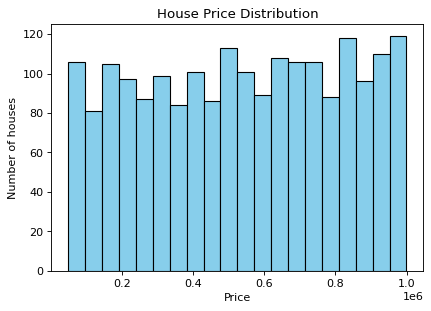

In [ ]:
# histogram to see how the price is distributed
plt.figure(figsize=(6, 4))
plt.hist(df['Price'], bins=20, color='skyblue', edgecolor='black')
plt.title('House Price Distribution')
plt.xlabel('Price')
plt.ylabel('Number of houses')
plt.show()

**Observation:** The prices are spread almost equally from 50,000 to 1,000,000. There is no big peak in the graph.

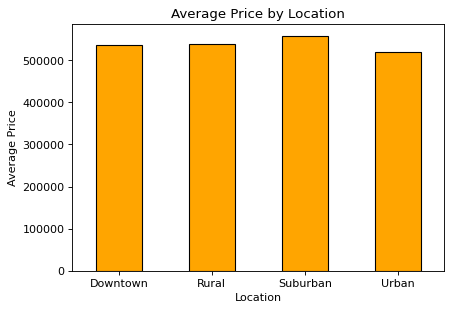

In [ ]:
# average price for each location
plt.figure(figsize=(6, 4))
df.groupby('Location')['Price'].mean().plot(kind='bar', color='orange', edgecolor='black')
plt.title('Average Price by Location')
plt.xlabel('Location')
plt.ylabel('Average Price')
plt.xticks(rotation=0)
plt.show()

**Observation:** The average price is almost the same in all four locations (around 520,000 to 560,000). So location alone is not changing the price much.

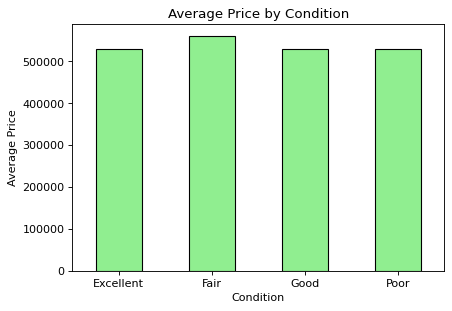

In [ ]:
# average price for each condition
plt.figure(figsize=(6, 4))
df.groupby('Condition')['Price'].mean().plot(kind='bar', color='lightgreen', edgecolor='black')
plt.title('Average Price by Condition')
plt.xlabel('Condition')
plt.ylabel('Average Price')
plt.xticks(rotation=0)
plt.show()

**Observation:** I expected Excellent houses to cost more, but the average price is almost similar for every condition.

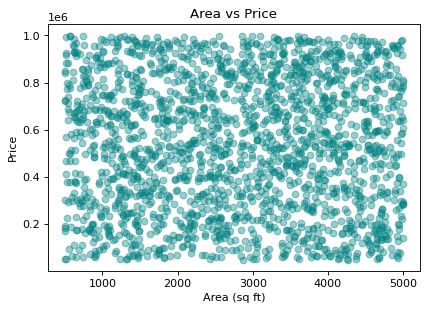

In [ ]:
# area vs price scatter plot
plt.figure(figsize=(6, 4))
plt.scatter(df['Area'], df['Price'], color='teal', alpha=0.4)
plt.title('Area vs Price')
plt.xlabel('Area (sq ft)')
plt.ylabel('Price')
plt.show()

**Observation:** The points are scattered everywhere. Bigger area does not mean higher price in this data.

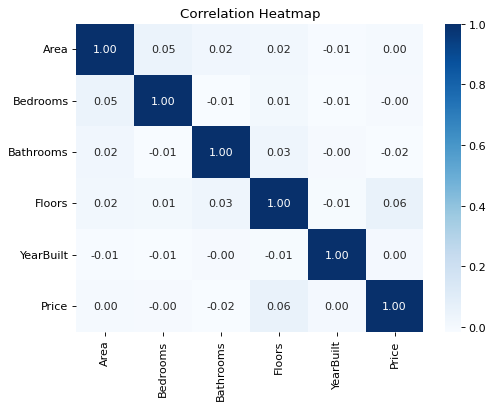

In [ ]:
# correlation heatmap
plt.figure(figsize=(7, 5))
num_cols = ['Area', 'Bedrooms', 'Bathrooms', 'Floors', 'YearBuilt', 'Price']
sns.heatmap(df[num_cols].corr(), annot=True, cmap='Blues', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

**Observation:** All the correlation values with `Price` are very close to 0. That means none of the numerical columns has a strong relation with the price. So the models may not perform very well on this dataset.

## 5. Encoding

Machine learning models can only work with numbers, so I am converting the text columns into numbers.

In [ ]:
# Garage: No = 0, Yes = 1
X['Garage'] = X['Garage'].map({'No': 0, 'Yes': 1})

In [ ]:
# Condition has an order (Poor < Fair < Good < Excellent), so I gave numbers 0 to 3
X['Condition'] = X['Condition'].map({'Poor': 0, 'Fair': 1, 'Good': 2, 'Excellent': 3})

In [ ]:
# Location has no order, so I am using get_dummies (one hot encoding)
X = pd.get_dummies(X, columns=['Location'], drop_first=True, dtype=int)
X.head()

,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Condition,Garage,Location_Rural,Location_Suburban,Location_Urban
0,1360,5,4,3,1970,3,0,0,0,0
1,4272,5,4,3,1958,3,0,0,0,0
2,3592,2,2,3,1938,2,0,0,0,0
3,966,4,2,2,1902,1,1,0,1,0
4,4926,1,4,2,1975,1,1,0,0,0


**Observation:** Now all the columns are numbers. `Location` became 3 new columns (Rural, Suburban, Urban). Downtown is dropped because if all three are 0 then it is Downtown.

## 6. Train-Test Split

In [ ]:
from sklearn.model_selection import train_test_split

# 70% for training and 30% for testing
# regression split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=7)

# classification split
Xc_train, Xc_test, yc_train, yc_test = train_test_split(X, y_class, test_size=0.3, random_state=7)

print("Training rows:", X_train.shape[0])
print("Testing rows :", X_test.shape[0])

Training rows: 1400
Testing rows : 600


**Observation:** 1400 rows are used to train the model and 600 rows are kept for testing.

## 7. Feature Scaling

Area is in thousands but bedrooms is only 1 to 5, so I am scaling the numerical columns using StandardScaler. I fit the scaler only on the training data so that test data stays unseen.

In [ ]:
from sklearn.preprocessing import StandardScaler

num_features = ['Area', 'Bedrooms', 'Bathrooms', 'Floors', 'YearBuilt']

# scaling for regression data
scaler = StandardScaler()
X_train[num_features] = scaler.fit_transform(X_train[num_features])
X_test[num_features] = scaler.transform(X_test[num_features])

# scaling for classification data
scaler_c = StandardScaler()
Xc_train[num_features] = scaler_c.fit_transform(Xc_train[num_features])
Xc_test[num_features] = scaler_c.transform(Xc_test[num_features])

X_train.head()

,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Condition,Garage,Location_Rural,Location_Suburban,Location_Urban
1178,1.677467,-1.403942,0.425036,-1.196343,-0.813389,3,0,0,0,1
307,1.094530,0.688519,-0.480672,0.024415,-0.058957,0,0,0,1,0
285,1.341394,1.386006,1.330743,0.024415,1.477848,0,1,1,0,0
611,1.562110,-1.403942,0.425036,1.245173,1.729325,0,0,0,0,0
649,0.618490,0.688519,-1.386380,-1.196343,-1.232518,1,1,1,0,0


**Observation:** The numerical columns now have mean 0 and standard deviation 1.

## 8. Training the Models

### 8.1 Linear Regression (Regression)

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

lr = LinearRegression()
lr.fit(X_train, y_train)

pred_lr = lr.predict(X_test)

mae = mean_absolute_error(y_test, pred_lr)
mse = mean_squared_error(y_test, pred_lr)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, pred_lr)

print("MAE  :", round(mae, 2))
print("MSE  :", round(mse, 2))
print("RMSE :", round(rmse, 2))
print("R2   :", round(r2, 4))

MAE  : 235248.58
MSE  : 74518524830.65
RMSE : 272980.81
R2   : -0.0069


**Observation:**
- MAE is around 235,000, which means on average the predicted price is wrong by about 2.35 lakh (in a range of 50,000 to 10,00,000). That is a big error.
- R2 score is almost 0 (slightly negative). This means the model is not better than just predicting the average price every time.
- This matches what I saw in EDA - the columns have almost no relation with the price.

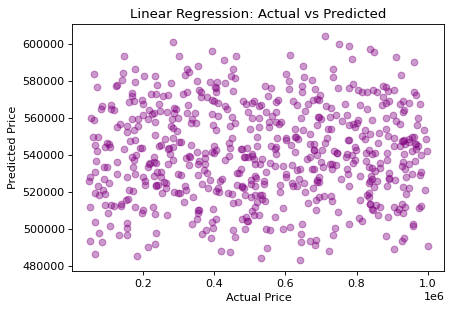

In [ ]:
# actual price vs predicted price
plt.figure(figsize=(6, 4))
plt.scatter(y_test, pred_lr, alpha=0.4, color='purple')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Linear Regression: Actual vs Predicted')
plt.show()

**Observation:** If the model was good, the points would form a straight line going upwards. Here the predictions are all in a small band in the middle, so the model is not learning much.

### 8.2 Classification Models (High price or Low price)

#### Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(Xc_train, yc_train)

pred_log = log_reg.predict(Xc_test)
print("Logistic Regression Accuracy:", round(accuracy_score(yc_test, pred_log) * 100, 2), "%")

Logistic Regression Accuracy: 50.67 %


#### KNN

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=7)
knn.fit(Xc_train, yc_train)

pred_knn = knn.predict(Xc_test)
print("KNN Accuracy:", round(accuracy_score(yc_test, pred_knn) * 100, 2), "%")

KNN Accuracy: 52.17 %


#### Decision Tree

I kept `max_depth=5` so the tree does not become too big and memorize the training data.

In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(max_depth=5, random_state=7)
dt.fit(Xc_train, yc_train)

pred_dt = dt.predict(Xc_test)
print("Decision Tree Accuracy:", round(accuracy_score(yc_test, pred_dt) * 100, 2), "%")

Decision Tree Accuracy: 50.33 %


#### Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=7)
rf.fit(Xc_train, yc_train)

pred_rf = rf.predict(Xc_test)
print("Random Forest Accuracy:", round(accuracy_score(yc_test, pred_rf) * 100, 2), "%")

Random Forest Accuracy: 52.83 %


#### SVM

In [ ]:
from sklearn.svm import SVC

svm = SVC()
svm.fit(Xc_train, yc_train)

pred_svm = svm.predict(Xc_test)
print("SVM Accuracy:", round(accuracy_score(yc_test, pred_svm) * 100, 2), "%")

SVM Accuracy: 51.83 %


**Observation:** All the models give accuracy near 50%. Since there are only 2 balanced classes, 50% is what we get by random guessing. So the models are not able to find any pattern in the data.

## 9. Model Evaluation

### Confusion Matrix (Logistic Regression)

[[136 175]
 [121 168]]


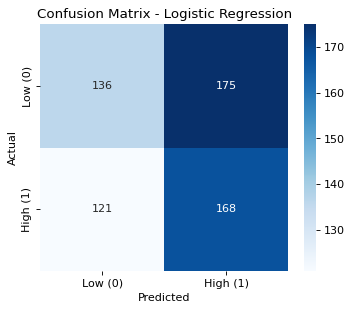

In [ ]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

cm = confusion_matrix(yc_test, pred_log)
print(cm)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Low (0)', 'High (1)'],
            yticklabels=['Low (0)', 'High (1)'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

In [ ]:
# accuracy, precision, recall and f1 score
print("Accuracy :", round(accuracy_score(yc_test, pred_log), 4))
print("Precision:", round(precision_score(yc_test, pred_log), 4))
print("Recall   :", round(recall_score(yc_test, pred_log), 4))
print("F1 Score :", round(f1_score(yc_test, pred_log), 4))

Accuracy : 0.5067
Precision: 0.4898
Recall   : 0.5813
F1 Score : 0.5316


**Observation:** In the confusion matrix, the diagonal boxes are the correct predictions and the other two boxes are the wrong ones. The wrong predictions are almost as many as the correct ones. Accuracy and precision are around 0.5 and recall and F1 are only a little higher, which is not good.

### Comparing all the classification models

In [ ]:
models = {
    "Logistic Regression": pred_log,
    "KNN": pred_knn,
    "Decision Tree": pred_dt,
    "Random Forest": pred_rf,
    "SVM": pred_svm
}

results = []
for name, pred in models.items():
    acc = accuracy_score(yc_test, pred) * 100
    results.append([name, round(acc, 2)])

accuracy_table = pd.DataFrame(results, columns=["Model", "Accuracy (%)"])
accuracy_table

,Model,Accuracy (%)
0,Logistic Regression,50.67
1,KNN,52.17
2,Decision Tree,50.33
3,Random Forest,52.83
4,SVM,51.83


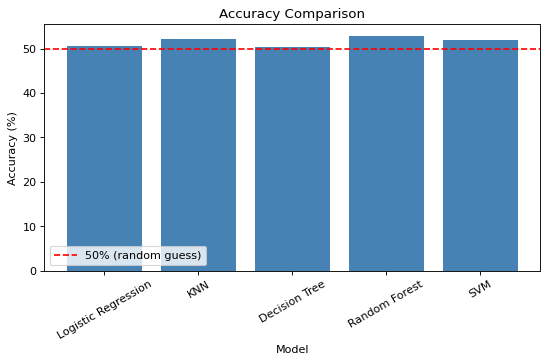

In [ ]:
# bar chart to compare accuracy
plt.figure(figsize=(8, 4))
plt.bar(accuracy_table["Model"], accuracy_table["Accuracy (%)"], color='steelblue')
plt.axhline(50, color='red', linestyle='--', label='50% (random guess)')
plt.xlabel('Model')
plt.ylabel('Accuracy (%)')
plt.title('Accuracy Comparison')
plt.xticks(rotation=30)
plt.legend()
plt.show()

**Observation:** Random Forest is slightly the best (about 52.8%), but all the models are around the 50% red line. No model is really better than random guessing.

## 10. Conclusion

- The dataset has 2000 houses with no missing values or duplicates, so it was ready to use after encoding.
- In EDA, no column showed a strong relation with `Price` (correlations were near 0).
- Linear Regression gave R2 near 0 and a high error (MAE about 2.35 lakh), so it could not predict the price properly.
- For classification (High / Low price), Logistic Regression, KNN, Decision Tree, Random Forest and SVM all gave about 50% to 53% accuracy, which is like random guessing.
- So the problem is not the algorithm, it is the data. The features in this dataset do not really explain the house price.
- What I learned: the full ML steps (understanding the data, EDA, encoding, splitting, scaling, training and evaluation). Also that a model is only as good as the data we give it.
- In future, a dataset with more useful columns (like distance to city, exact locality, etc.) can be tried to get better results.